# M3 – Thử nghiệm: dự đoán reference từ ngữ cảnh trích dẫn

Notebook này **chỉ đọc kết quả** do các script trong `src/m3/context/` tạo ra (ghi vào `data/m3_all/context/`); nó không train gì. Thứ tự chạy:

```bash
python src/m3/context/contexts.py     --tables data/tables_all/tables --out data/m3_all/context   # ~2.5 phút
python src/m3/context/corpus_links.py --work data/m3_all                                          # ~1 phút
python src/m3/context/ctx_features.py --work data/m3_all                                          # ~9 phút
python src/m3/context/analyze_ctx.py  --work data/m3_all                                          # ~25 phút
python src/m3/context/train_ctx.py    --work data/m3_all --ctx-set compact
python src/m3/context/train_ctx.py    --work data/m3_all --ctx-set full --test                    # test: một lần
python src/m3/context/select_meta_ctx.py --work data/m3_all                                       # ~9 phút
```

Notebook chính `src/m3/notebooks/m3_features_model.ipynb` không đổi.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from matplotlib.patches import Patch

pd.set_option("display.max_colwidth", 200)
WORK = Path("../../../../data/m3_all")
CTX = WORK / "context"
colors = {"ctx_title": "tab:blue", "ctx_desc": "tab:orange", "ctx_author": "tab:green", "ctx_year": "tab:purple",
          "ctx_entry": "tab:gray"}

## 1. Vì sao có thử nghiệm này

Ở model chính, bài toán **dễ**: entry BibTeX có title, tác giả, năm, thường cả arXiv id hay DOI, nên so với ứng viên là gần như ra đáp án (MRR@5 ≈ 1; chỉ riêng author + year + venue cũng đạt 0,95 ở ca khó).

Ở đây ta hỏi một câu khó hơn: **chỉ từ đoạn văn trích dẫn** (câu có `\cite{...}`, câu láng giềng, tiêu đề section, caption), không nhìn bất kỳ trường nào của entry, có đoán được bài nào đang được trích không? Đây là bài toán *citation resolution / local citation recommendation*.

Giữ nguyên mọi thứ của model chính để so sánh được:
- cùng nhãn (`labels.csv`), cùng split, cùng ứng viên (reference có arXiv id của chính bài, trung bình 45 ứng viên/entry có nhãn);
- cùng metric MRR@5 (hoà điểm tính bất lợi), cùng 5 fold theo bài trên train để chọn cấu hình; test chấm **một lần**.

**Chống rò rỉ:** key như `zheng2024large` chứa sẵn tác giả và năm → mọi `\cite` của entry thành từ `zzcitezz`, của entry khác thành `zzotherzz`; key không bao giờ vào văn bản. Không dùng trường BibTeX nào. Không dùng model huấn luyện sẵn hay dữ liệu ngoài: TF-IDF và LSA được fit trên corpus của nhóm.

## 2. Ngữ cảnh trích dẫn từ cây M2

`contexts.py` đọc bảng `elements` + `hierarchy` của M2. Trong cây, `\cite` vẫn còn trong câu với **key chuẩn** của bảng `bibtex` (bước đổi tên key của M2), nên mỗi câu nối thẳng với entry. Một dòng = một lần trích (element × key), gồm:
- `left` / `right`: tối đa 15 từ trước / 8 từ sau chỗ trích, dừng ở trích dẫn khác (câu "A [1], B [2], C [3]" thì [2] chỉ nhận cụm B);
- `sentence`: câu quanh chỗ trích (±60 từ; figure: chỉ caption);
- `neighbours`: câu trước và sau cùng cha trong cây; `headings`, `section` (loại section từ heading cấp cao nhất);
- công thức → `zzmathzz`, bỏ `\ref`, `\label`, URL, lệnh định dạng; chữ thường ASCII (`text_clean.normalize_text`).

Element được chia sẻ giữa các version (M2 dedup) nên mỗi element tính một lần, vị trí lấy ở version mới nhất có nó.

2,131,928 lần trích trong 23,115 bài; 1,116,681 entry được trích ít nhất một lần


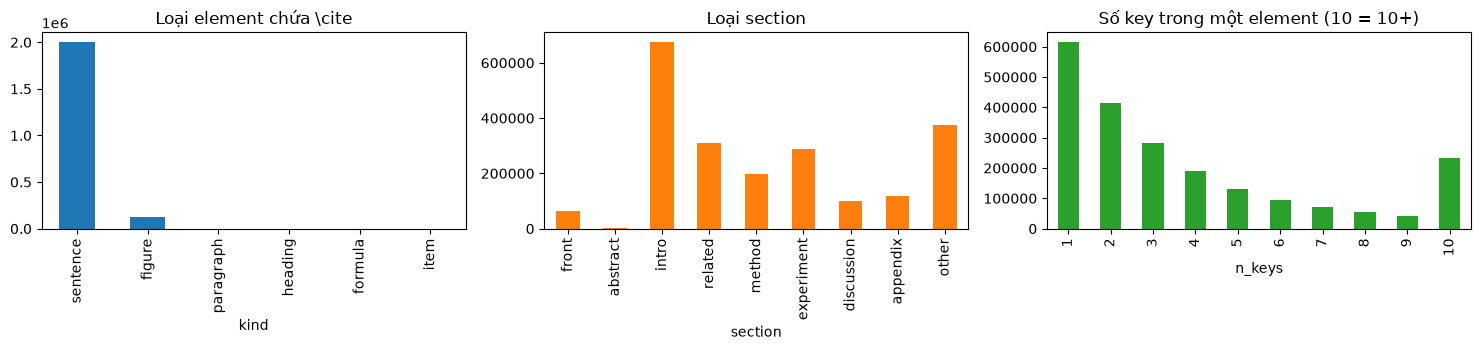

Entry có nhãn: 63,612; có ngữ cảnh: 99.12%


In [2]:
men = pq.read_table(CTX / "mentions.parquet", columns=["arxiv_id", "citation_key", "kind", "section", "n_keys"]).to_pandas()
print(f"{len(men):,} lần trích trong {men.arxiv_id.nunique():,} bài; "
      f"{men.groupby(['arxiv_id', 'citation_key']).ngroups:,} entry được trích ít nhất một lần")
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
men.kind.value_counts().plot.bar(ax=ax[0], color="tab:blue"); ax[0].set_title("Loại element chứa \\cite")
order = ["front", "abstract", "intro", "related", "method", "experiment", "discussion", "appendix", "other"]
men.section.value_counts().reindex(order).plot.bar(ax=ax[1], color="tab:orange"); ax[1].set_title("Loại section")
men.n_keys.clip(upper=10).value_counts().sort_index().plot.bar(ax=ax[2], color="tab:green")
ax[2].set_title("Số key trong một element (10 = 10+)")
plt.tight_layout(); plt.show()
F = pq.read_table(CTX / "features.parquet", columns=["group", "y", "is_sample", "ctx_missing", "n_desc",
                                                     "desc_missing"]).to_pandas()
gold = F[F.y == 1]
print(f"Entry có nhãn: {len(gold):,}; có ngữ cảnh: {(gold.ctx_missing == 0).mean():.2%}")

In [3]:
lab = pd.read_csv(WORK / "labels.csv", dtype=str)
ex = pq.read_table(CTX / "mentions.parquet", columns=["arxiv_id", "citation_key", "section", "headings", "left", "right",
                                                      "sentence"]).to_pandas()
ex = ex.merge(lab[lab.is_match == "true"][["arxiv_id", "citation_key"]]).sample(4, random_state=3)
ex[["citation_key", "section", "headings", "left", "right", "sentence"]]

,citation_key,section,headings,left,right,sentence
106117,jiang2023active,related,related work multi hop retrieval augmented generation,prior work tackles this through iterative retrieve and reason prompting,graph based reasoning over retrieved content,prior work tackles this through iterative retrieve and reason prompting zzcitezz graph based reasoning over retrieved content zzotherzz and rl trained search policies zzotherzz
108682,cai2021robustcur,intro,introduction,corrupted low rank recovery problems including robust pca and robust cur decompositions for imaging applications,,cur type methods have also been used in corrupted low rank recovery problems including robust pca and robust cur decompositions for imaging applications zzcitezz
21999,agmon2024finding,method,problem formulation pattern removal,of equality predicates in line with past work on explanations that deem such predicates understandable,,our patterns are restricted to conjunctions of equality predicates in line with past work on explanations that deem such predicates understandable zzcitezz
99664,doh2023toward,intro,introduction,captioning,or classification,despite this most existing music benchmarks zzotherzz focus on single item tagging zzotherzz captioning zzcitezz or classification zzotherzz and do not directly test a models ability to reason acr...


## 3. Mô tả ứng viên bằng chính corpus (thay cho abstract)

Title của ứng viên quá ngắn để so với một câu văn. Thay vì lấy abstract từ ngoài, ta mô tả mỗi ứng viên bằng **những gì các bài khác trong corpus viết khi trích nó**:
- `corpus_links.py` nối entry → arXiv id trên **toàn bộ** 23 000 bài, chỉ bằng luật chắc chắn R1–R3 của `auto_label.py` (cùng id, cùng DOI, cùng title), không R4, không model, không đọc nhãn;
- mô tả của ứng viên = ngữ cảnh (local + câu) của mọi entry trong **bài khác** nối tới nó; với mỗi bài đang xét, phần đóng góp của chính bài đó luôn được trừ ra.

Kiểm tra: số bài khác mô tả ứng viên đúng và ứng viên sai có phân bố gần như nhau (hình dưới), tức đặc trưng này không lộ đáp án qua số lượng.

436,511 liên kết chắc chắn trong 20,001 bài: {'R3': 186892, 'R1': 167100, 'R2': 82519}
Trùng với nhãn: 62,903 entry, cùng đáp án: 100.00%


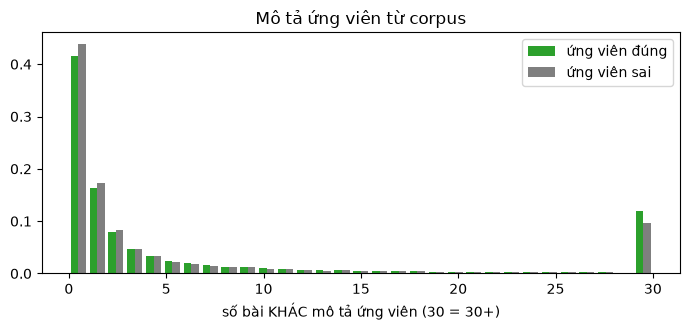

Ứng viên đúng không có mô tả: 40.3%


In [4]:
links = pq.read_table(CTX / "links.parquet").to_pandas()
print(f"{len(links):,} liên kết chắc chắn trong {links.arxiv_id.nunique():,} bài:", links.rule.value_counts().to_dict())
both = lab[lab.is_match == "true"].merge(links, on=["arxiv_id", "citation_key"])
print(f"Trùng với nhãn: {len(both):,} entry, cùng đáp án: {(both.label_ref_arxiv_id == both.ref_arxiv_id).mean():.2%}")
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.hist([np.expm1(F.loc[F.y == 1, "n_desc"]).clip(upper=30), np.expm1(F.loc[F.y == 0, "n_desc"]).clip(upper=30)],
        bins=31, density=True, label=["ứng viên đúng", "ứng viên sai"], color=["tab:green", "tab:gray"])
ax.set_xlabel("số bài KHÁC mô tả ứng viên (30 = 30+)"); ax.legend(); ax.set_title("Mô tả ứng viên từ corpus")
plt.tight_layout(); plt.show()
print(f"Ứng viên đúng không có mô tả: {gold.desc_missing.mean():.1%}")

## 4. Feature engineering (1): từng đặc trưng một mình

27 đặc trưng ngữ cảnh, 5 nhóm (`ctx_features.CTX_GROUPS`):
- **ctx_title:** cosine TF-IDF giữa local / câu / toàn ngữ cảnh và title ứng viên, cosine LSA, hạng và khoảng cách tới ứng viên tốt nhất trong nhóm;
- **ctx_desc:** như trên nhưng với mô tả từ bài khác; số bài mô tả (`n_desc`), cờ thiếu mô tả;
- **ctx_author:** họ tác giả đầu của ứng viên có trong cụm local / ngữ cảnh ("altman et al [CITE]"), số họ tác giả xuất hiện;
- **ctx_year:** tuổi ứng viên so với bài đang xét và hạng của nó;
- **ctx_entry:** giống nhau cho mọi ứng viên của entry (số lần trích, số key trung bình trong câu, vị trí, section, tỉ lệ trong figure, số ứng viên) – chỉ có ích qua tương tác.

Đường đứt: mức ngẫu nhiên (0,088).

,feature,group,mrr5_alone,mean_yes,mean_no,missing
0,sim_local_title,ctx_title,0.3283,0.1032,0.0214,0.0000
1,sim_sent_title,ctx_title,0.3231,0.1040,0.0296,0.0000
4,rank_sent_title,ctx_title,0.3231,8.4797,26.5231,0.0000
5,gap_sent_title,ctx_title,0.3231,0.0927,0.1715,0.0000
7,sim_local_desc,ctx_desc,0.2859,0.1415,0.0283,0.3951
2,sim_all_title,ctx_title,0.2770,0.1036,0.0434,0.0000
10,rank_sent_desc,ctx_desc,0.2748,17.4302,40.4884,0.0000
8,sim_sent_desc,ctx_desc,0.2658,0.1410,0.0395,0.3951
11,gap_sent_desc,ctx_desc,0.2658,0.0619,0.1456,0.3951
6,rank_lsa_title,ctx_title,0.2244,14.9996,41.2894,0.0000


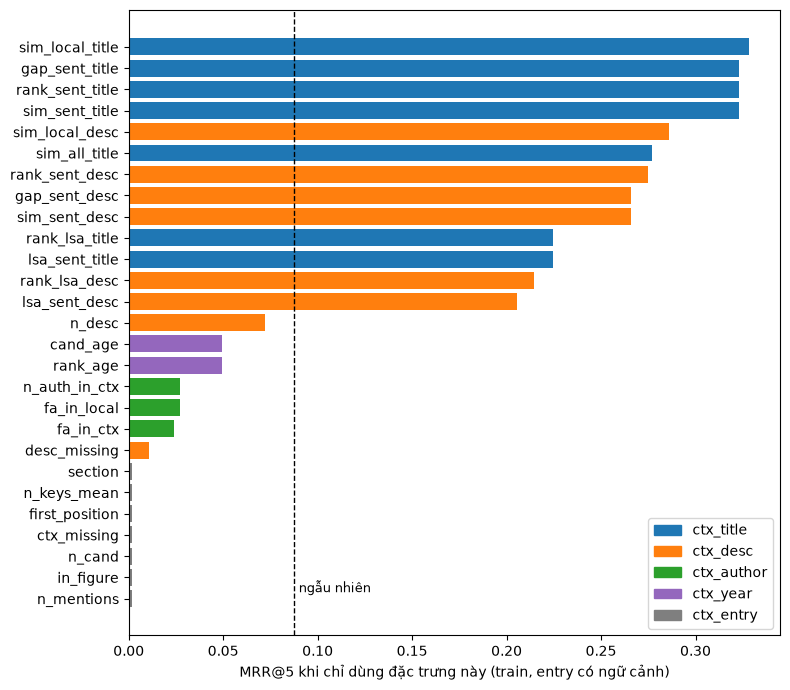

In [5]:
rep = pd.read_csv(CTX / "ctx_feature_report.csv")
display(rep.sort_values("mrr5_alone", ascending=False))
r = rep.sort_values("mrr5_alone")
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(r.feature, r.mrr5_alone, color=[colors[g] for g in r.group])
ax.axvline(0.0875, color="k", ls="--", lw=1); ax.text(0.09, 0.3, "ngẫu nhiên", fontsize=9)
ax.legend(handles=[Patch(color=v, label=k) for k, v in colors.items()], loc="lower right")
ax.set_xlabel("MRR@5 khi chỉ dùng đặc trưng này (train, entry có ngữ cảnh)")
plt.tight_layout(); plt.show()

## 5. Feature engineering (2): ablation theo nhóm và permutation importance (CV trên train)

**Model chỉ dùng ngữ cảnh:**
- bỏ **ctx_title** mất 0,10 MRR@5 (0,12 ở ca khó): so câu trích với title là tín hiệu chính;
- bỏ **ctx_desc** mất 0,06: mô tả từ bài khác (phương án nội bộ thay abstract) đóng góp thật;
- **ctx_author** khoảng 0,01; **ctx_year** và **ctx_entry** gần 0.

Permutation importance xác nhận: `sim_local_desc`, `sim_local_title` (cụm từ sát chỗ trích) quan trọng nhất, rồi `n_desc`, `fa_in_local`, `n_keys_mean`.

**Model metadata + ngữ cảnh (ca khó, không link):** bỏ từng nhóm ngữ cảnh chỉ thay đổi ±0,001 (trong nhiễu); bỏ cả 27 đặc trưng ngữ cảnh mất 0,0026. Ở model kết hợp, ngữ cảnh giúp như một khối, nên bộ đặc trưng cho model này được chọn riêng (mục 5.3).

,model,removed,features,mrr5,mrr5_hard,drop,drop_hard
0,ctx,(none),27,0.4416,0.3593,0.0000,0.0000
1,ctx,ctx_title,20,0.3403,0.2379,0.1013,0.1214
2,ctx,ctx_desc,19,0.3802,0.3162,0.0614,0.0431
3,ctx,ctx_author,24,0.4296,0.3476,0.0120,0.0117
4,ctx,ctx_year,25,0.4414,0.3577,0.0002,0.0016
5,ctx,ctx_entry,20,0.4391,0.3562,0.0025,0.0031
6,meta+ctx (no link),(none),44,0.9994,0.9875,0.0000,0.0000
7,meta+ctx (no link),ctx_title,37,0.9993,0.9863,0.0001,0.0012
8,meta+ctx (no link),ctx_desc,36,0.9994,0.9878,0.0000,-0.0003
9,meta+ctx (no link),ctx_author,41,0.9994,0.9874,0.0000,0.0001


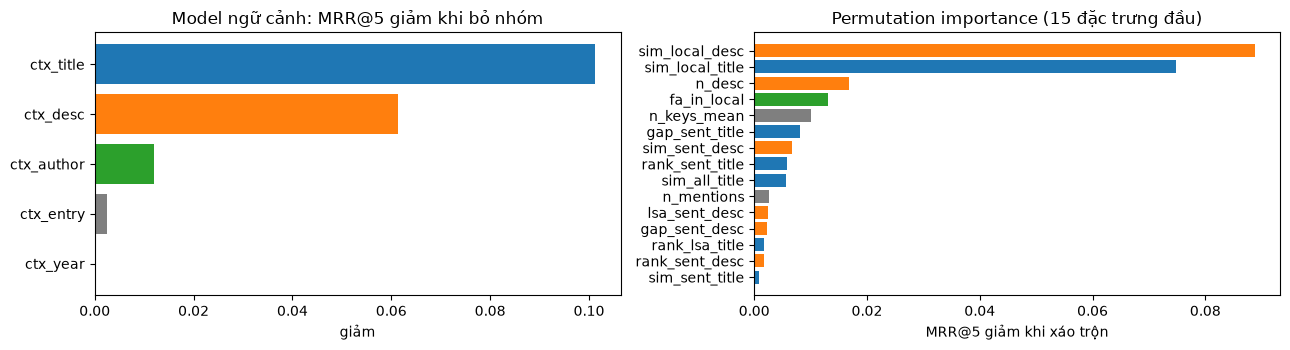

In [6]:
abl = pd.read_csv(CTX / "ctx_ablation_cv.csv")
display(abl)
a = abl[(abl.model == "ctx") & (abl.removed != "(none)")].sort_values("drop")
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
ax[0].barh(a.removed, a["drop"], color=[colors[g] for g in a.removed], label="mọi entry")
ax[0].set_title("Model ngữ cảnh: MRR@5 giảm khi bỏ nhóm"); ax[0].set_xlabel("giảm")
imp = pd.read_csv(CTX / "ctx_importance_cv.csv").sort_values("mrr5_drop").tail(15)
ax[1].barh(imp.feature, imp.mrr5_drop, color=[colors[g] for g in imp.group])
ax[1].set_title("Permutation importance (15 đặc trưng đầu)"); ax[1].set_xlabel("MRR@5 giảm khi xáo trộn")
plt.tight_layout(); plt.show()

### 5.1 Tương quan giữa các đặc trưng ngữ cảnh

Khác với nhóm title ở model chính (ba độ giống title tương quan > 0,9), các đặc trưng ngữ cảnh ít trùng lặp: chỉ hai cặp có |r| > 0,8 – `sim_local_desc` / `sim_sent_desc` (0,83: cụm local nằm trong câu) và `rank_sent_desc` / `rank_lsa_desc` (0,97: khi ứng viên không có mô tả, cả hai hạng cùng bằng hạng cuối). Cụm từ local và cả câu, TF-IDF và LSA mang thông tin khác nhau, nên không bỏ theo tương quan mà theo importance (5.2).

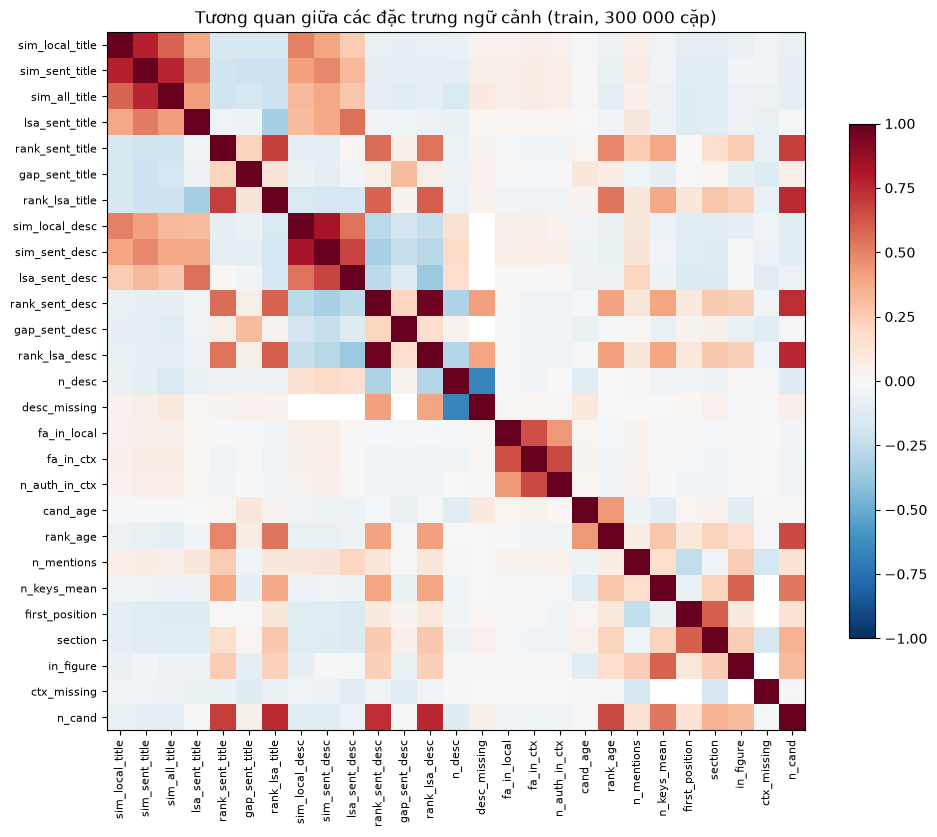

,đặc trưng 1,đặc trưng 2,r
1,rank_sent_desc,rank_lsa_desc,0.975
0,sim_local_desc,sim_sent_desc,0.825


In [7]:
CTXF = [f for g in json.loads((CTX / "features_ctx.json").read_text(encoding="utf-8"))["groups"].values() for f in g]
cols = ["is_sample", "arxiv_id"] + CTXF
sample = pq.read_table(CTX / "features.parquet", columns=cols).to_pandas()
splits = json.loads((WORK / "splits.json").read_text(encoding="utf-8"))
sample = sample[(sample.is_sample == 1) & sample.arxiv_id.isin(set(splits["train"]))].sample(300_000, random_state=0)
corr = sample[CTXF].corr()
fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(CTXF))); ax.set_xticklabels(CTXF, rotation=90, fontsize=8)
ax.set_yticks(range(len(CTXF))); ax.set_yticklabels(CTXF, fontsize=8)
plt.colorbar(im, ax=ax, shrink=0.7); ax.set_title("Tương quan giữa các đặc trưng ngữ cảnh (train, 300 000 cặp)")
plt.tight_layout(); plt.show()
pairs_hi = [(a, b, round(corr.loc[a, b], 3)) for i, a in enumerate(CTXF) for b in CTXF[i + 1:] if abs(corr.loc[a, b]) > 0.8]
pd.DataFrame(pairs_hi, columns=["đặc trưng 1", "đặc trưng 2", "r"]).sort_values("r", key=abs, ascending=False)

### 5.2 Chọn bộ đặc trưng cho model chỉ ngữ cảnh

Từ mục 4–5, bộ **compact** giữ 13 đặc trưng có permutation importance rõ, một hai đặc trưng mỗi tín hiệu (`ctx_features.CTX_COMPACT`); bỏ nhóm năm, hạng LSA, LSA của title, section / vị trí / tỉ lệ figure. So bằng CV: compact kém full 0,003 ở `ctx+assign` (bỏ 14 đặc trưng yếu cộng lại vẫn mất một ít) → chọn **full (27)** cho model chỉ ngữ cảnh, trước khi xem test.

In [8]:
def cv_table(path):
    r = json.loads(Path(path).read_text(encoding="utf-8"))
    return pd.DataFrame({n: {"all": v["all"]["mrr5"], "có ngữ cảnh": v["with_context"]["mrr5"],
                             "ca khó": v["hard"]["mrr5"], "hit@1 (có ngữ cảnh)": v["with_context"]["hit1"]}
                         for n, v in r["cv"].items()}).T

full, compact = cv_table(CTX / "ctx_cv_report_full.json"), cv_table(CTX / "ctx_cv_report_compact.json")
print("Bộ compact:", ", ".join(json.loads((CTX / "ctx_cv_report_compact.json").read_text(encoding="utf-8"))["features"]["ctx"]))
pd.DataFrame({"full (27)": full.loc[["ctx", "ctx+assign"], "có ngữ cảnh"],
              "compact (13)": compact.loc[["ctx", "ctx+assign"], "có ngữ cảnh"]}).style.format("{:.4f}").set_caption(
    "Model chỉ ngữ cảnh, MRR@5 CV (entry có ngữ cảnh)")

Bộ compact: sim_local_title, sim_all_title, rank_sent_title, gap_sent_title, sim_local_desc, sim_sent_desc, gap_sent_desc, lsa_sent_desc, n_desc, fa_in_local, n_auth_in_ctx, n_keys_mean, n_mentions


,full (27),compact (13)
ctx,0.4416,0.4393
ctx+assign,0.4586,0.4552


### 5.3 Chọn bộ đặc trưng cho model kết hợp (metadata + ngữ cảnh)

17 đặc trưng metadata giữ nguyên (kết quả feature engineering của model chính, để `meta` đúng là model chính); chỉ chọn **thêm bao nhiêu đặc trưng ngữ cảnh** (`select_meta_ctx.py`, CV trên train, cùng fold):
- `meta` (17) – model chính;
- `meta+ctx4` (21) – thêm 4 đặc trưng có importance cao nhất: `sim_local_title`, `sim_local_desc`, `n_desc`, `fa_in_local`;
- `meta+ctx13` (30) – thêm bộ compact; `meta+ctx27` (44) – thêm tất cả.

Mỗi bộ đo có và không có ràng buộc 1–1. Khóa chọn như model chính: trung bình MRR@5 của all, all không link và khó không link (có 1–1); chọn **bộ nhỏ nhất** cách bộ tốt nhất không quá 0,0005.

**Kết quả:** khóa 0,99657 (meta) → 0,99717 (+4) → 0,99750 (+13) → 0,99743 (+27). Bộ +13 tốt nhất nhưng +4 chỉ kém 0,0003 với ít hơn 9 đặc trưng → chọn **`meta+ctx4` (21 đặc trưng)**. Thêm cả 27 không hơn thêm 13: các đặc trưng ngữ cảnh yếu không giúp gì khi đã có metadata. Hình: lỗi ở ca khó không link giảm dần theo số đặc trưng ngữ cảnh, và ràng buộc 1–1 giảm lỗi ở mọi bộ.

Bộ được chọn: meta+ctx4 | 4 đặc trưng mạnh nhất: sim_local_title, sim_local_desc, n_desc, fa_in_local


,all,all +1-1,no link,no link +1-1,khó no link,khó no link +1-1,khóa chọn
meta (17),0.9999,1.0000,0.9992,0.9995,0.9849,0.9902,0.9966
meta+ctx4 (21),1.0000,1.0000,0.9993,0.9996,0.9865,0.9919,0.9972
meta+ctx13 (30),1.0000,1.0000,0.9994,0.9996,0.9880,0.9929,0.9975
meta+ctx27 (44),1.0000,1.0000,0.9994,0.9996,0.9875,0.9927,0.9974


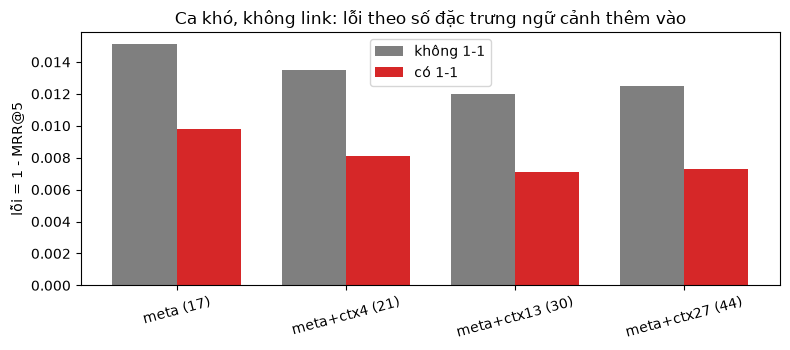

In [9]:
sel = json.loads((CTX / "select_meta_ctx.json").read_text(encoding="utf-8"))
rows = {}
for n, r in sel["cv"].items():
    rows[f"{n} ({sel['options'][n]})"] = {
        "all": r["all"]["mrr5"], "all +1-1": r["all+assign"]["mrr5"],
        "no link": r["all_nolink"]["mrr5"], "no link +1-1": r["all_nolink+assign"]["mrr5"],
        "khó no link": r["hard_nolink"]["mrr5"], "khó no link +1-1": r["hard_nolink+assign"]["mrr5"],
        "khóa chọn": np.mean([r[k]["mrr5"] for k in ("all+assign", "all_nolink+assign", "hard_nolink+assign")])}
seltab = pd.DataFrame(rows).T
print("Bộ được chọn:", sel["chosen"], "| 4 đặc trưng mạnh nhất:", ", ".join(sel["top4"]))
display(seltab.style.format("{:.4f}").set_caption("Model kết hợp: CV trên train"))
fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(len(seltab)); w = 0.38
ax.bar(x - w / 2, 1 - seltab["khó no link"], w, label="không 1-1", color="tab:gray")
ax.bar(x + w / 2, 1 - seltab["khó no link +1-1"], w, label="có 1-1", color="tab:red")
ax.set_xticks(x); ax.set_xticklabels(seltab.index, rotation=15); ax.set_ylabel("lỗi = 1 - MRR@5")
ax.set_title("Ca khó, không link: lỗi theo số đặc trưng ngữ cảnh thêm vào"); ax.legend()
plt.tight_layout(); plt.show()

## 6. So sánh model: CV 5 fold trên train

| Tên | Là gì |
|---|---|
| `random` | thứ tự ngẫu nhiên (mức sàn) |
| `tfidf_title` | cosine TF-IDF câu trích ↔ title ứng viên |
| `tfidf_desc` | cosine TF-IDF câu trích ↔ mô tả từ bài khác |
| `ctx` | LightGBM lambdarank, **chỉ** đặc trưng ngữ cảnh |
| `ctx+assign` | `ctx` + **ràng buộc 1–1**: hai entry của cùng bài không trích cùng một reference. Giải bài toán gán (Hungarian) trên điểm của mọi entry của bài (cả entry không có nhãn), mỗi entry được phép "không chọn ai" với ngưỡng θ chọn trên CV; ứng viên được gán lên đầu |
| `meta` | cấu hình model chính (17 đặc trưng compact, che link 50% khi train) |
| `meta+ctx` | 17 đặc trưng metadata + đặc trưng ngữ cảnh |
| `(no link)` | chấm khi che arXiv id và DOI của entry |

Cột "có ngữ cảnh": bỏ ~0,9% entry không được `\cite` ở đâu trong văn bản (chỉ có trong .bib, `\nocite`, ...): model ngữ cảnh không thể biết chúng. "Ca khó": title của cặp đúng không trùng y hệt.

Bảng dưới dùng bộ full (27) cho cả `ctx` và `meta+ctx`; bộ được chọn cho model kết hợp ở mục 5.3 và 7.1.

,all,có ngữ cảnh,ca khó,hit@1 (có ngữ cảnh)
random,0.0879,0.0875,0.0894,0.0383
tfidf_title,0.3204,0.3231,0.2698,0.2254
tfidf_desc,0.2619,0.2642,0.1616,0.1906
ctx,0.4390,0.4416,0.3559,0.3341
meta,0.9999,0.9999,0.9983,0.9998
meta+ctx,1.0000,1.0000,0.9994,0.9999
ctx+assign,0.4560,0.4586,0.3611,0.3591
ctx (no link),0.4390,0.4416,0.3559,0.3341
meta (no link),0.9992,0.9993,0.9849,0.9989
meta+ctx (no link),0.9994,0.9994,0.9875,0.9990


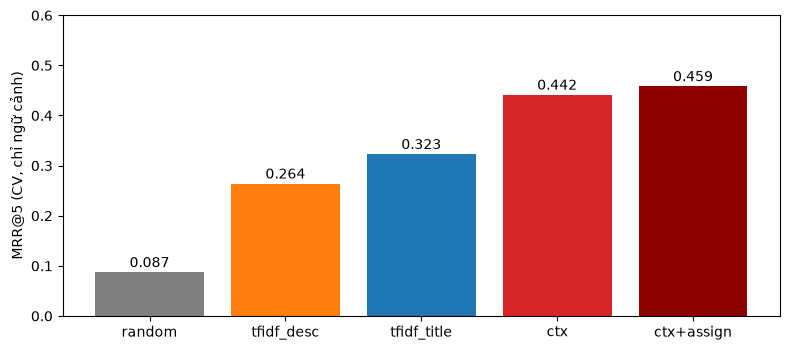

In [10]:
display(full.style.format("{:.4f}").set_caption("CV, bộ full (27 đặc trưng ngữ cảnh)"))
names = ["random", "tfidf_desc", "tfidf_title", "ctx", "ctx+assign"]
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(names, full.loc[names, "có ngữ cảnh"], color=["tab:gray", "tab:orange", "tab:blue", "tab:red", "darkred"])
for i, v in enumerate(full.loc[names, "có ngữ cảnh"]):
    ax.text(i, v + 0.01, f"{v:.3f}", ha="center")
ax.set_ylabel("MRR@5 (CV, chỉ ngữ cảnh)"); ax.set_ylim(0, 0.6); plt.tight_layout(); plt.show()

## 7. Kết quả trên tập test (chấm một lần)

Test chỉ có 346 entry có nhãn (338 có ngữ cảnh, 29 ca khó) từ 10 bài, nên dao động lớn: sai số chuẩn của MRR@5 cỡ ±0,02 trên toàn bộ và ±0,08 trên 29 ca khó.

- Chỉ ngữ cảnh: `ctx` 0,395 (CV 0,442), `tfidf_title` 0,310, ngẫu nhiên 0,059. Thấp hơn CV nhưng cùng thứ tự và cách xa mức ngẫu nhiên.
- Ràng buộc 1–1 trên test: gần như không đổi trên toàn bộ (0,395 → 0,392), tăng ở ca khó (0,386 → 0,435). Trên CV nó tăng đều (+0,017), nên test 10 bài quá nhỏ để kết luận khác.
- Metadata không link: `meta` 0,9986 (ca khó 0,983) → `meta+ctx` **1,000** (ca khó 1,000).

In [11]:
te = json.loads((CTX / "ctx_test_report.json").read_text(encoding="utf-8"))
print("Bộ đặc trưng:", te.pop("ctx_set"))
pd.DataFrame({n: {"all": v["all"]["mrr5"], "có ngữ cảnh": v["with_context"]["mrr5"], "ca khó": v["hard"]["mrr5"],
                  "hit@1": v["with_context"]["hit1"], "entry": v["all"]["entries"], "entry khó": v["hard"]["entries"]}
              for n, v in te.items()}).T

Bộ đặc trưng: full


,all,có ngữ cảnh,ca khó,hit@1,entry,entry khó
random,0.0598,0.0586,0.0862,0.0266,346.0,29.0
tfidf_title,0.3027,0.3099,0.3201,0.2071,346.0,29.0
tfidf_desc,0.2235,0.2287,0.1489,0.1568,346.0,29.0
ctx,0.3866,0.3948,0.3862,0.2870,346.0,29.0
meta,1.0000,1.0000,1.0000,1.0000,346.0,29.0
meta+ctx,1.0000,1.0000,1.0000,1.0000,346.0,29.0
ctx+assign,0.3840,0.3921,0.4351,0.2870,346.0,29.0
ctx (no link),0.3866,0.3948,0.3862,0.2870,346.0,29.0
meta (no link),0.9986,0.9985,0.9828,0.9970,346.0,29.0
meta+ctx (no link),1.0000,1.0000,1.0000,1.0000,346.0,29.0


### 7.1 Model kết hợp đã chọn so với model chính, trên từng tập

`meta` và `meta+ctx4` được fit trên toàn bộ train, chấm trên valid và test (θ của ràng buộc 1–1 lấy từ CV). Cột **do 1-1** = phần tăng khi chỉ thêm ràng buộc 1–1 vào `meta`; **do ngữ cảnh** = phần tăng thêm khi có 4 đặc trưng ngữ cảnh; **lỗi giảm** = phần lỗi của `meta` được sửa.

Đọc bảng:
- **Train (CV, 62 866 entry, 3 119 ca khó):** ở ca khó không link, MRR@5 0,9849 → **0,9919**, lỗi giảm **46%**: ràng buộc 1–1 đóng góp +0,0053 (0,9849 → 0,9902), ngữ cảnh thêm +0,0017. Ở ca khó có link: 0,9983 → 0,9994. Trên toàn bộ entry model chính đã ~1 nên tăng không đáng kể.
- **Valid (400 entry, 22 ca khó):** cả hai model đều 1,000 ở mọi cột – tập valid quá dễ (như ở notebook chính), không phân biệt được.
- **Test (346 entry, 29 ca khó):** không link, `meta` 0,9986 (ca khó 0,9828) → `meta+ctx4` 1,000 (ca khó 1,000). Riêng ràng buộc 1–1 trên `meta` cũng đã lên 1,000, nên trên test không tách được phần của ngữ cảnh: chỉ có vài entry sai để sửa.

Tóm lại: con số đáng tin là CV – thêm ngữ cảnh và ràng buộc 1–1 sửa khoảng **một nửa lỗi** của model chính ở ca khó khi không có link, trong đó phần lớn nhờ ràng buộc 1–1.

In [12]:
ch = sel["chosen"]
metrics = [("all", "all"), ("no link", "all_nolink"), ("khó", "hard"), ("khó, no link", "hard_nolink")]
out = []
for part, src in (("train (CV)", sel["cv"]), ("valid", sel["valid"]), ("test", sel["test"])):
    for label, k in metrics:
        b, b1 = src["meta"][k]["mrr5"], src["meta"][k + "+assign"]["mrr5"]
        c1, c2 = src[ch][k]["mrr5"], src[ch][k + "+assign"]["mrr5"]
        out.append({"tập": part, "đo trên": label, "entry": src["meta"][k]["entries"], "meta": b, "meta +1-1": b1,
                    ch: c1, f"{ch} +1-1": c2, "tăng (so với meta)": c2 - b,
                    "do 1-1": b1 - b, "do ngữ cảnh": c2 - b1,
                    "lỗi giảm": (c2 - b) / (1 - b) if b < 1 else np.nan})
gain = pd.DataFrame(out).set_index(["tập", "đo trên"])
gain.style.format({"meta": "{:.4f}", "meta +1-1": "{:.4f}", ch: "{:.4f}", f"{ch} +1-1": "{:.4f}",
                   "tăng (so với meta)": "{:+.4f}", "do 1-1": "{:+.4f}", "do ngữ cảnh": "{:+.4f}",
                   "lỗi giảm": "{:.0%}"}, na_rep="-")

### 7.2 Kiểm chứng rò rỉ: mô tả ứng viên ở chế độ chặt

Mô tả ứng viên bằng câu trích của bài khác có hai rủi ro: dùng bài **đăng sau** bài đang xét (thông tin tương lai), và bài **cùng tác giả** chép lại gần nguyên câu. Để đo, `ctx_features.py --strict` tính lại mô tả chỉ từ các bài **đăng trước** (ngày nộp M1) và **không chung tác giả** với bài đang xét (thư mục `context_strict/`), rồi chạy lại đúng các bước CV.

Đọc bảng:
- **Model kết hợp không đổi:** `meta+ctx4` + 1–1 ở ca khó không link 0,9919 ở cả hai chế độ (bộ được chọn vẫn là +4). Kết luận của mục 5.3 và 7.1 không phụ thuộc vào rủi ro này.
- **Model chỉ ngữ cảnh giảm 0,018** (0,459 → 0,440); `tfidf_desc` giảm 0,057. Một phần vì chế độ chặt có ít mô tả hơn hẳn (ứng viên đúng không có mô tả: 40% → 56%, vì chỉ còn khoảng một nửa số bài là đăng trước), một phần là phần lợi từ bài sau / cùng tác giả. Vì không tách được hai phần, con số **0,44** của chế độ chặt là con số thận trọng nên báo cáo cho model chỉ ngữ cảnh.
- Mô tả vẫn đóng góp ở chế độ chặt: `ctx` 0,426 so với 0,380 khi bỏ hẳn nhóm mô tả (mục 5).

In [13]:
STRICT = WORK / "context_strict"
def ctx_row(path):
    r = json.loads(Path(path).read_text(encoding="utf-8"))["cv"]
    return {n: r[n]["with_context"]["mrr5"] for n in ("tfidf_desc", "ctx", "ctx+assign")}
def comb_row(path):
    r = json.loads(Path(path).read_text(encoding="utf-8"))["cv"]
    return {f"{n} khó no link +1-1": r[n]["hard_nolink+assign"]["mrr5"] for n in ("meta", "meta+ctx4", "meta+ctx13")}
leak = pd.DataFrame({"mô tả thường": {**ctx_row(CTX / "ctx_cv_report_full.json"), **comb_row(CTX / "select_meta_ctx.json")},
                     "mô tả chặt": {**ctx_row(STRICT / "ctx_cv_report_full.json"), **comb_row(STRICT / "select_meta_ctx.json")}})
leak["chênh"] = leak["mô tả chặt"] - leak["mô tả thường"]
for d, name in ((CTX, "thường"), (STRICT, "chặt")):
    f = pq.read_table(d / "features.parquet", columns=["y", "is_sample", "desc_missing"]).to_pandas()
    print(f"mô tả {name}: ứng viên đúng không có mô tả {f[(f.is_sample == 1) & (f.y == 1)].desc_missing.mean():.1%}")
leak.style.format({"mô tả thường": "{:.4f}", "mô tả chặt": "{:.4f}", "chênh": "{:+.4f}"}).set_caption("CV trên train")

mô tả thường: ứng viên đúng không có mô tả 40.3%
mô tả chặt: ứng viên đúng không có mô tả 55.8%


,mô tả thường,mô tả chặt,chênh
tfidf_desc,0.2642,0.2069,-0.0573
ctx,0.4416,0.4261,-0.0155
ctx+assign,0.4586,0.4402,-0.0184
meta khó no link +1-1,0.9902,0.9902,+0.0000
meta+ctx4 khó no link +1-1,0.9919,0.9919,+0.0000
meta+ctx13 khó no link +1-1,0.9929,0.9931,+0.0002


## 8. Ví dụ (out-of-fold trên train, model `ctx+assign`)

Ba entry đoán đúng hạng 1 và ba entry đoán sai, với câu trích đầu tiên (đã che key), đáp án và ứng viên được chọn. Các lỗi thường gặp: câu trích chung nhiều reference, câu chỉ nói chung ("following prior work [CITE]"), hay hai ứng viên cùng chủ đề.

In [14]:
oof = pq.read_table(CTX / "oof_scores_full.parquet", columns=["group", "ref_arxiv_id", "y", "is_sample", "s_ctx_assign"]).to_pandas()
oof = oof[oof.is_sample]
top = oof.sort_values("s_ctx_assign", ascending=False).drop_duplicates("group")
gold_ = oof[oof.y == 1][["group", "ref_arxiv_id"]].rename(columns={"ref_arxiv_id": "gold"})
top = top.merge(gold_, on="group")
top["right"] = top.ref_arxiv_id == top.gold
refs = pq.read_table(WORK / "references_clean.parquet", columns=["ref_arxiv_id", "ref_title"]).to_pandas()
title = dict(zip(refs.ref_arxiv_id, refs.ref_title))
first = ex_all = pq.read_table(CTX / "mentions.parquet", columns=["arxiv_id", "citation_key", "sentence"]).to_pandas()
first = first.drop_duplicates(["arxiv_id", "citation_key"])
first["group"] = first.arxiv_id + "|" + first.citation_key
sample = pd.concat([top[top.right].sample(3, random_state=1), top[~top.right].sample(3, random_state=1)])
sample = sample.merge(first[["group", "sentence"]], on="group", how="left")
for _, r in sample.iterrows():
    print(("ĐÚNG" if r.right else "SAI "), "|", r.group)
    print("   câu   :", (r.sentence or "")[:300])
    print("   đáp án:", title.get(r.gold))
    if not r.right:
        print("   đoán  :", title.get(r.ref_arxiv_id))
    print()

ĐÚNG | 2512.16116|Trappeniers
   câu   : more recently trappeniers zzcitezz studied two sided skew braces and showed that every two sided skew brace is an extension of a weakly trivial skew brace by a two sided brace
   đáp án: On Two-sided Skew Braces

ĐÚNG | 2512.15240|Harris2020
   câu   : data analysis and visualization were performed using numpy zzcitezz matplotlib zzotherzz vesta zzotherzz and gnuplot zzotherzz
   đáp án: Array programming with NumPy

ĐÚNG | 2512.14499|MMCAMD
   câu   : age related macular degeneration amd detection was evaluated on adam zzotherzz china and mmc amd zzcitezz china
   đáp án: Learning Two-Stream CNN for Multi-Modal Age-Related Macular Degeneration Categorization

SAI  | 2512.00845|cuerdaObservationQuantumMetric2024
   câu   : in recent years several efforts have focused on understanding how concepts of topology and band theory are manifested in diverse nanostructured systems like photonic zzotherzz magnonic zzotherzz or plasmonic crystals zzcitezz 

## 9. Hạn chế và kết luận

**Hạn chế:**
- Ngữ cảnh mỏng: trung vị **một** câu trích cho mỗi reference; 42% câu trích nhiều reference cùng lúc.
- Khoảng 40% ứng viên đúng không có mô tả từ bài khác (không bài nào khác trong corpus trích nó bằng liên kết chắc chắn), chỉ còn title.
- Không dùng abstract (cần dữ liệu ngoài, phải hỏi thầy) hay embedding huấn luyện sẵn; cả hai có thể tăng mạnh phần chỉ-ngữ-cảnh.
- Test 10 bài quá nhỏ cho bài toán khó này; CV trên 2 515 bài train là con số đáng tin hơn.
- Nhãn vẫn lệch về phía dễ (luật auto ưu tiên precision) như ở notebook chính.

**Kết luận:**
- Bỏ metadata của entry, bài toán trở nên khó thật: chỉ từ ngữ cảnh, model đạt MRR@5 **0,46** trên CV (hit@1 36%; **0,44** khi mô tả chỉ lấy từ bài đăng trước, không chung tác giả – mục 7.2), so với 0,09 ngẫu nhiên và 0,32 TF-IDF.
- Tín hiệu mạnh nhất là **cụm từ ngay sát chỗ trích** so với title, và **mô tả ứng viên bằng câu trích của các bài khác** – một cách mô tả hoàn toàn từ dữ liệu của nhóm.
- **Ràng buộc 1–1** (mỗi reference chỉ ứng với một entry) giúp thêm ~0,02 trên CV.
- **Feature engineering:** model chỉ ngữ cảnh dùng đủ 27 đặc trưng (bộ 13 kém 0,003); model kết hợp chỉ cần thêm **4** đặc trưng ngữ cảnh vào 17 đặc trưng metadata (21 đặc trưng) – thêm nhiều hơn không giúp.
- Gắn vào model chính, 4 đặc trưng ngữ cảnh + ràng buộc 1–1 **giảm 46% lỗi ở ca khó khi không có link** (CV 0,9849 → 0,9919; phần lớn nhờ 1–1, ngữ cảnh thêm 0,0017; test 0,983 → 1,000; valid đều 1,000). Đây là chỗ hierarchy của M2 có ích cho bài toán matching.